In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 

In [2]:
df = pd.read_csv("data-export (1).csv")

In [3]:
df.head()

,# ----------------------------------------,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9
0,Session primary channel group (Default channel...,Date + hour (YYYYMMDDHH),Users,Sessions,Engaged sessions,Average engagement time per session,Engaged sessions per user,Events per session,Engagement rate,Event count
1,Direct,2024041623,237,300,144,47.526666666666700,0.6075949367088610,4.673333333333330,0.48,1402
2,Organic Social,2024041719,208,267,132,32.09737827715360,0.6346153846153850,4.295880149812730,0.4943820224719100,1147
3,Direct,2024041723,188,233,115,39.93991416309010,0.6117021276595740,4.587982832618030,0.49356223175965700,1069
4,Organic Social,2024041718,187,256,125,32.16015625,0.6684491978609630,4.078125,0.48828125,1044


In [8]:
df.columns = df.iloc[0]
df = df.drop(index=0).reset_index(drop = True)
df.columns = ["channel group","Datehour","User", "Sessions","Engaged session" ,"Average engagement time per session",	"Engaged sessions per user",	"Events per session",	"Engagement rate",	"Event count"]

In [9]:
df.head()

,channel group,Datehour,User,Sessions,Engaged session,Average engagement time per session,Engaged sessions per user,Events per session,Engagement rate,Event count
0,Direct,2024041623,237,300,144,47.526666666666700,0.6075949367088610,4.673333333333330,0.48,1402
1,Organic Social,2024041719,208,267,132,32.09737827715360,0.6346153846153850,4.295880149812730,0.4943820224719100,1147
2,Direct,2024041723,188,233,115,39.93991416309010,0.6117021276595740,4.587982832618030,0.49356223175965700,1069
3,Organic Social,2024041718,187,256,125,32.16015625,0.6684491978609630,4.078125,0.48828125,1044
4,Organic Social,2024041720,175,221,112,46.918552036199100,0.64,4.529411764705880,0.5067873303167420,1001


In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3182 entries, 0 to 3181
Data columns (total 10 columns):
 #   Column                               Non-Null Count  Dtype
---  ------                               --------------  -----
 0   channel group                        3182 non-null   str  
 1   Datehour                             3182 non-null   str  
 2   User                                 3182 non-null   str  
 3   Sessions                             3182 non-null   str  
 4   Engaged session                      3182 non-null   str  
 5   Average engagement time per session  3182 non-null   str  
 6   Engaged sessions per user            3182 non-null   str  
 7   Events per session                   3182 non-null   str  
 8   Engagement rate                      3182 non-null   str  
 9   Event count                          3182 non-null   str  
dtypes: str(10)
memory usage: 506.9 KB


In [17]:
df["Datehour"]= pd.to_datetime(df["Datehour"],format="%Y%m%d%H", errors='coerce')
numeric_cols = df.columns.drop(["channel group","Datehour"])
df[numeric_cols] = df[numeric_cols].apply(pd.to_numeric,errors='coerce')
df["hour"]= df["Datehour"].dt.hour


In [18]:
df.head()


,channel group,Datehour,User,Sessions,Engaged session,Average engagement time per session,Engaged sessions per user,Events per session,Engagement rate,Event count,hour
0,Direct,2024-04-16 23:00:00,237,300,144,47.526667,0.607595,4.673333,0.480000,1402,23
1,Organic Social,2024-04-17 19:00:00,208,267,132,32.097378,0.634615,4.295880,0.494382,1147,19
2,Direct,2024-04-17 23:00:00,188,233,115,39.939914,0.611702,4.587983,0.493562,1069,23
3,Organic Social,2024-04-17 18:00:00,187,256,125,32.160156,0.668449,4.078125,0.488281,1044,18
4,Organic Social,2024-04-17 20:00:00,175,221,112,46.918552,0.640000,4.529412,0.506787,1001,20


In [19]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3182 entries, 0 to 3181
Data columns (total 11 columns):
 #   Column                               Non-Null Count  Dtype         
---  ------                               --------------  -----         
 0   channel group                        3182 non-null   str           
 1   Datehour                             3182 non-null   datetime64[us]
 2   User                                 3182 non-null   int64         
 3   Sessions                             3182 non-null   int64         
 4   Engaged session                      3182 non-null   int64         
 5   Average engagement time per session  3182 non-null   float64       
 6   Engaged sessions per user            3182 non-null   float64       
 7   Events per session                   3182 non-null   float64       
 8   Engagement rate                      3182 non-null   float64       
 9   Event count                          3182 non-null   int64         
 10  hour                   

In [20]:
df.describe()

,Datehour,User,Sessions,Engaged session,Average engagement time per session,Engaged sessions per user,Events per session,Engagement rate,Event count,hour
count,3182,3182.000000,3182.000000,3182.000000,3182.000000,3182.000000,3182.000000,3182.000000,3182.000000,3182.000000
mean,2024-04-20 01:17:07.278441,41.935889,51.192646,28.325581,66.644581,0.606450,4.675969,0.503396,242.272470,11.807040
min,2024-04-06 00:00:00,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,0.000000
25%,2024-04-13 02:15:00,20.000000,24.000000,13.000000,32.103034,0.561404,3.750000,0.442902,103.000000,6.000000
50%,2024-04-20 02:00:00,42.000000,51.000000,27.000000,49.020202,0.666667,4.410256,0.545455,226.000000,12.000000
75%,2024-04-26 22:00:00,60.000000,71.000000,41.000000,71.487069,0.750000,5.217690,0.633333,339.000000,18.000000
max,2024-05-03 23:00:00,237.000000,300.000000,144.000000,4525.000000,2.000000,56.000000,1.000000,1402.000000,23.000000
std,NaN,29.582258,36.919962,20.650569,127.200659,0.264023,2.795228,0.228206,184.440313,6.886686


# session and user over time

In [21]:
sns.set(style="whitegrid")

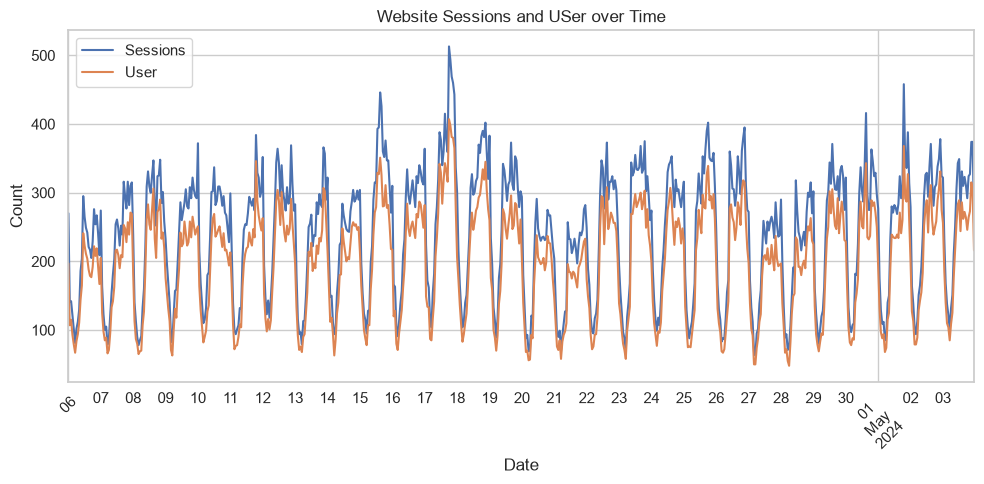

In [24]:
import matplotlib.pyplot as plt 
plt.figure(figsize=(10,5))
df.groupby("Datehour")[["Sessions","User"]].sum().plot(ax=plt.gca())

plt.title("Website Sessions and USer over Time")
plt.xlabel("Date")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# total user by channel

C:\Users\Sampa\AppData\Local\Temp\ipykernel_13936\340873248.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x="channel group", y="User", estimator=np.sum, palette="viridis")


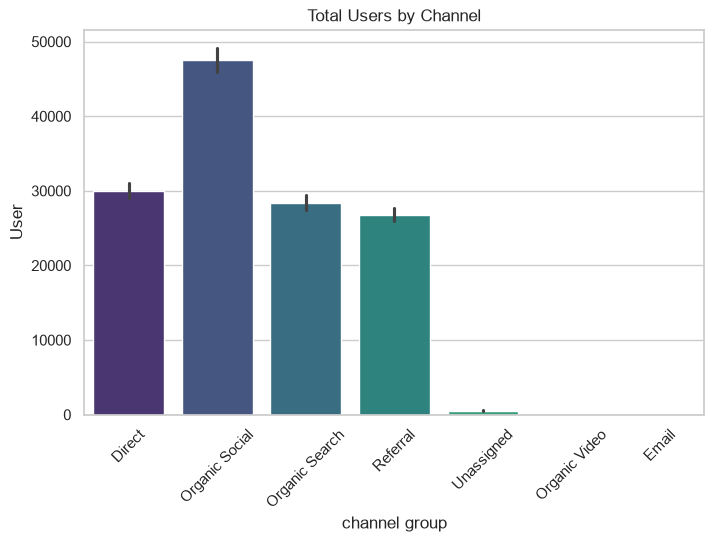

In [25]:
plt.figure(figsize= (8,5))
sns.barplot(data=df, x="channel group", y="User", estimator=np.sum, palette="viridis")
plt.title("Total Users by Channel")
plt.xticks(rotation=45)
plt.show()

# Average engagement time by channel

C:\Users\Sampa\AppData\Local\Temp\ipykernel_13936\3010322565.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x="channel group", y="Average engagement time per session", estimator=np.mean, palette="magma")


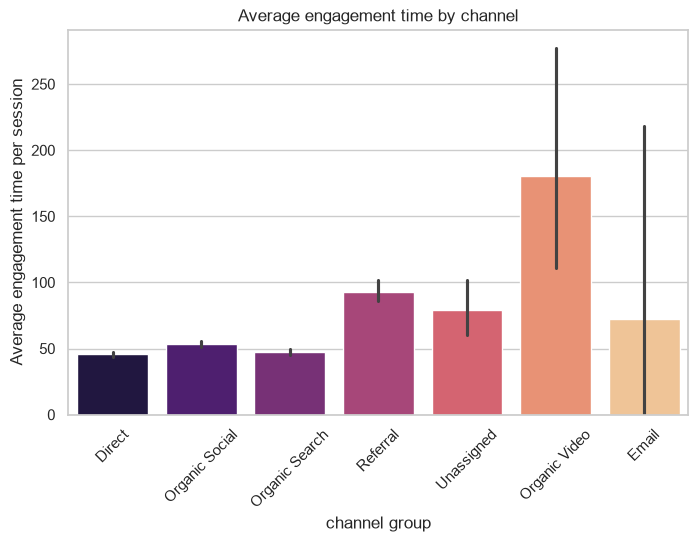

In [27]:
plt.figure(figsize=(8,5))
sns.barplot(data=df, x="channel group", y="Average engagement time per session", estimator=np.mean, palette="magma")
plt.title("Average engagement time by channel")
plt.xticks(rotation=45)
plt.show()

# Enagagement rate distribution by channel

C:\Users\Sampa\AppData\Local\Temp\ipykernel_13936\2114323751.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x="channel group", y="Engagement rate", palette="coolwarm")


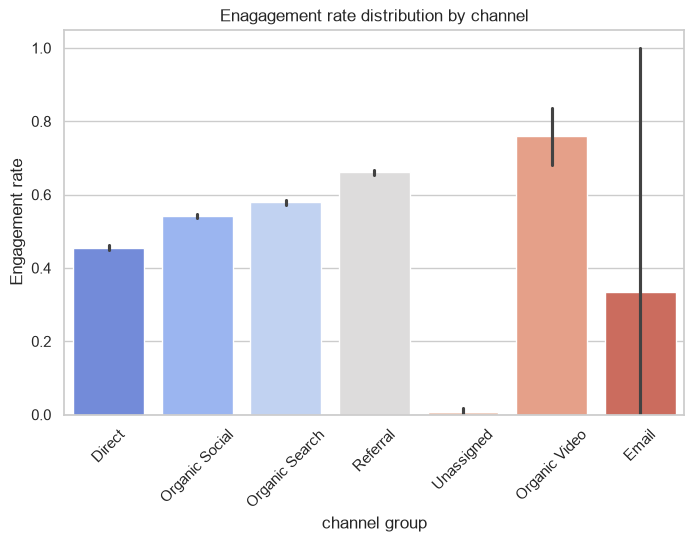

In [28]:
plt.figure(figsize=(8,5))
sns.barplot(data=df, x="channel group", y="Engagement rate", palette="coolwarm")
plt.title("Enagagement rate distribution by channel")
plt.xticks(rotation=45)
plt.show()

# Engaged vs non engaged sessions

In [29]:
df.head()

,channel group,Datehour,User,Sessions,Engaged session,Average engagement time per session,Engaged sessions per user,Events per session,Engagement rate,Event count,hour
0,Direct,2024-04-16 23:00:00,237,300,144,47.526667,0.607595,4.673333,0.480000,1402,23
1,Organic Social,2024-04-17 19:00:00,208,267,132,32.097378,0.634615,4.295880,0.494382,1147,19
2,Direct,2024-04-17 23:00:00,188,233,115,39.939914,0.611702,4.587983,0.493562,1069,23
3,Organic Social,2024-04-17 18:00:00,187,256,125,32.160156,0.668449,4.078125,0.488281,1044,18
4,Organic Social,2024-04-17 20:00:00,175,221,112,46.918552,0.640000,4.529412,0.506787,1001,20


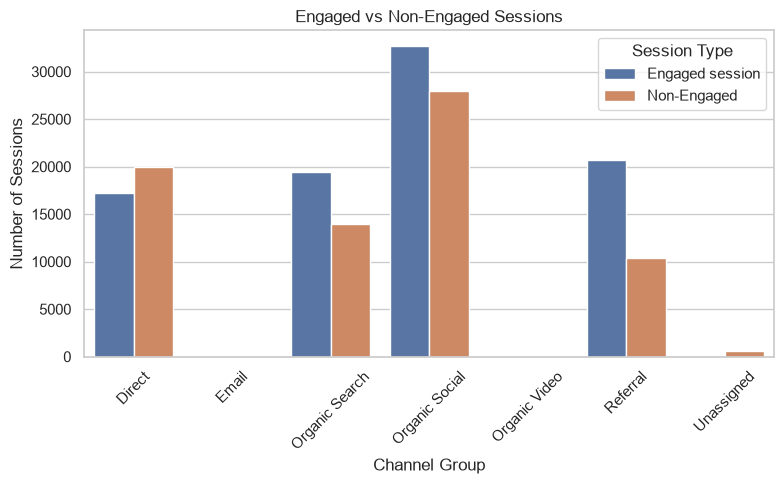

In [32]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Group sessions by channel
session_df = df.groupby("channel group")[
    ["Sessions", "Engaged session"]
].sum().reset_index()

# Calculate non-engaged sessions
session_df["Non-Engaged"] = (
    session_df["Sessions"] - session_df["Engaged session"]
)

# Reshape data for visualization
session_df_melted = session_df.melt(
    id_vars="channel group",
    value_vars=["Engaged session", "Non-Engaged"],
    var_name="Session Type",
    value_name="Count"
)

# Create the chart
plt.figure(figsize=(8, 5))

sns.barplot(
    data=session_df_melted,
    x="channel group",
    y="Count",
    hue="Session Type"
)

plt.title("Engaged vs Non-Engaged Sessions")
plt.xlabel("Channel Group")
plt.ylabel("Number of Sessions")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# traffic by hour and channel

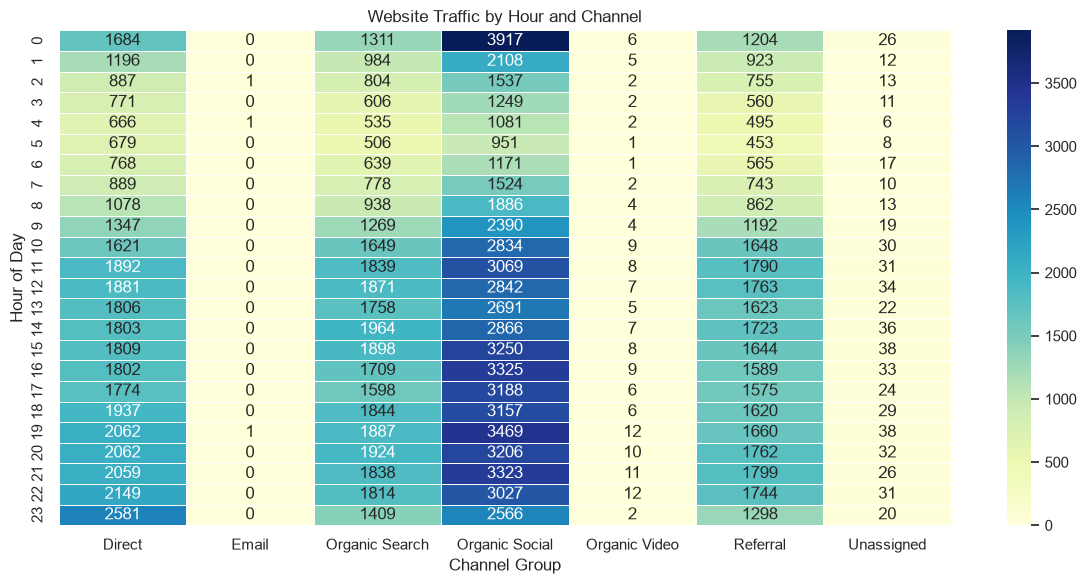

In [35]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Convert Datehour to datetime if it is not already
df["Datehour"] = pd.to_datetime(df["Datehour"], errors="coerce")

# Extract the hour from Datehour
df["hour"] = df["Datehour"].dt.hour

# Group sessions by hour and channel
heatmap_data = df.groupby(
    ["hour", "channel group"]
)["Sessions"].sum().unstack(fill_value=0)

# Create heatmap
plt.figure(figsize=(12, 6))

sns.heatmap(
    heatmap_data,
    cmap="YlGnBu",
    linewidths=0.5,
    annot=True,
    fmt=".0f"
)

plt.title("Website Traffic by Hour and Channel")
plt.xlabel("Channel Group")
plt.ylabel("Hour of Day")
plt.tight_layout()
plt.show()